In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [21]:
data = pd.read_csv("/content/Wine_SVM_Dataset (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", data.shape)

display(data.head())

Dataset loaded successfully!
Dataset shape: (130, 14)


,cultivar,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,Cultivar_1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,Cultivar_1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,Cultivar_1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,Cultivar_1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,Cultivar_1,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [22]:
print("Class distribution:")
print(data["cultivar"].value_counts())

print("\nFirst 5 rows:")
display(
    data[["proline", "color_intensity", "cultivar"]].head()
)

Class distribution:
cultivar
Cultivar_2    71
Cultivar_1    59
Name: count, dtype: int64

First 5 rows:


,proline,color_intensity,cultivar
0,1065.0,5.64,Cultivar_1
1,1050.0,4.38,Cultivar_1
2,1185.0,5.68,Cultivar_1
3,1480.0,7.80,Cultivar_1
4,735.0,4.32,Cultivar_1


In [23]:
data["Class"] = data["cultivar"].map({
    "Cultivar_1": 0,
    "Cultivar_2": 1
})

print("Class conversion completed.")

display(
    data[["proline", "color_intensity", "cultivar", "Class"]].head()
)

Class conversion completed.


,proline,color_intensity,cultivar,Class
0,1065.0,5.64,Cultivar_1,0
1,1050.0,4.38,Cultivar_1,0
2,1185.0,5.68,Cultivar_1,0
3,1480.0,7.80,Cultivar_1,0
4,735.0,4.32,Cultivar_1,0


In [24]:
X = data[["proline", "color_intensity"]]

y = data["Class"]

print("Features:")
display(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Features:


,proline,color_intensity
0,1065.0,5.64
1,1050.0,4.38
2,1185.0,5.68
3,1480.0,7.80
4,735.0,4.32



Target distribution:
Class
1    71
0    59
Name: count, dtype: int64


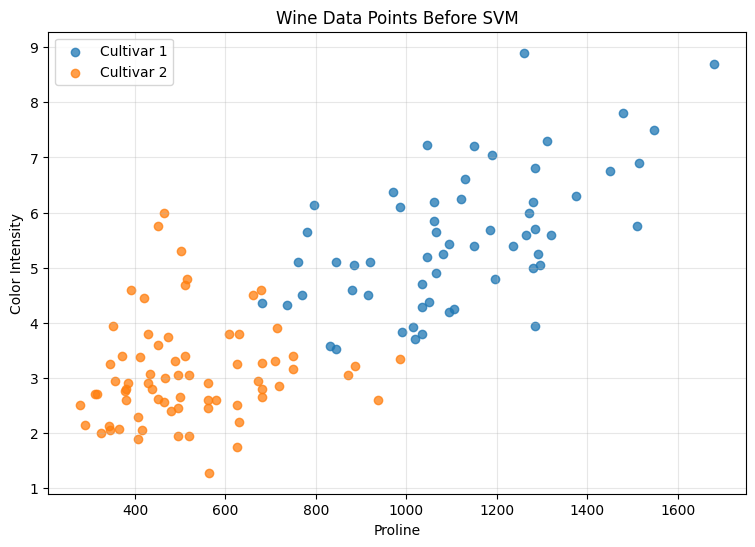

In [25]:
plt.figure(figsize=(9, 6))

for label, name in [
    (0, "Cultivar 1"),
    (1, "Cultivar 2")
]:

    mask = y == label

    plt.scatter(
        X.loc[mask, "proline"],
        X.loc[mask, "color_intensity"],
        label=name,
        alpha=0.75
    )

plt.xlabel("Proline")
plt.ylabel("Color Intensity")
plt.title("Wine Data Points Before SVM")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 104
Testing samples: 26


In [27]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [28]:
svm_model = SVC(
    kernel="linear",
    C=1.0
)

svm_model.fit(
    X_train_scaled,
    y_train
)

print("SVM model trained successfully!")

SVM model trained successfully!


In [29]:
y_pred = svm_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)

Predictions:
[0 0 1 1 0 0 1 1 0 1 0 1 1 0 1 0 0 0 0 1 1 1 0 1 0 1]


In [30]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.9615384615384616
Accuracy (%): 96.15384615384616


In [31]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[12  0]
 [ 1 13]]


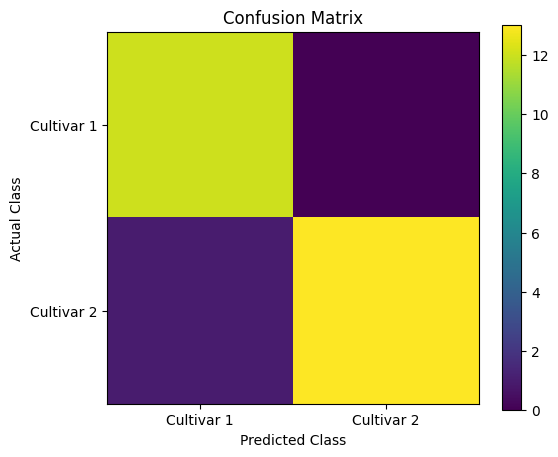

In [32]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Cultivar 1", "Cultivar 2"]
)

plt.yticks(
    [0, 1],
    ["Cultivar 1", "Cultivar 2"]
)

plt.colorbar()

plt.show()

In [33]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Cultivar 1",
            "Cultivar 2"
        ]
    )
)

Classification Report:
              precision    recall  f1-score   support

  Cultivar 1       0.92      1.00      0.96        12
  Cultivar 2       1.00      0.93      0.96        14

    accuracy                           0.96        26
   macro avg       0.96      0.96      0.96        26
weighted avg       0.96      0.96      0.96        26



In [34]:
print("SVM Coefficients:")
print(svm_model.coef_)

print("\nSVM Intercept:")
print(svm_model.intercept_)

print("\nNumber of Support Vectors:")
print(svm_model.n_support_)

SVM Coefficients:
[[-1.83112859 -1.64899044]]

SVM Intercept:
[0.09241947]

Number of Support Vectors:
[ 9 10]


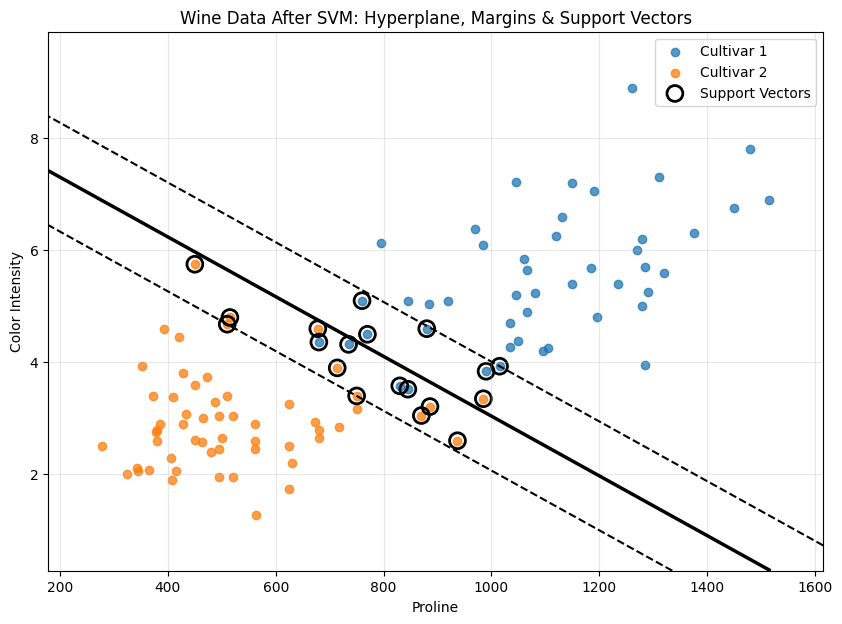

In [35]:
plt.figure(figsize=(10, 7))

# Plot training points
for label, name in [
    (0, "Cultivar 1"),
    (1, "Cultivar 2")
]:

    mask = y_train.values == label

    plt.scatter(
        X_train.iloc[mask]["proline"],
        X_train.iloc[mask]["color_intensity"],
        label=name,
        alpha=0.75
    )

# Feature limits
x_min = X_train["proline"].min() - 100
x_max = X_train["proline"].max() + 100

y_min = X_train["color_intensity"].min() - 1
y_max = X_train["color_intensity"].max() + 1

# Create grid
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Convert grid into DataFrame
grid_original = pd.DataFrame(
    np.c_[
        xx.ravel(),
        yy.ravel()
    ],
    columns=[
        "proline",
        "color_intensity"
    ]
)

# Scale grid
grid_scaled = scaler.transform(
    grid_original
)

# Calculate decision function
Z = svm_model.decision_function(
    grid_scaled
).reshape(xx.shape)

# Draw hyperplane and margins
plt.contour(
    xx,
    yy,
    Z,
    levels=[-1, 0, 1],
    colors="k",
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2.5, 1.5]
)

# Convert support vectors back to original scale
support_vectors_original = scaler.inverse_transform(
    svm_model.support_vectors_
)

# Plot support vectors
plt.scatter(
    support_vectors_original[:, 0],
    support_vectors_original[:, 1],
    s=130,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)

plt.xlabel("Proline")
plt.ylabel("Color Intensity")

plt.title(
    "Wine Data After SVM: Hyperplane, Margins & Support Vectors"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

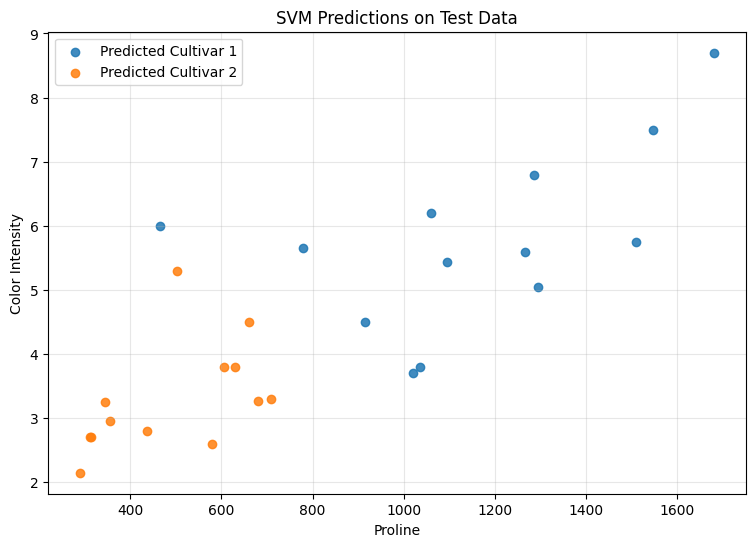

In [36]:
plt.figure(figsize=(9, 6))

for label, name in [
    (0, "Predicted Cultivar 1"),
    (1, "Predicted Cultivar 2")
]:

    mask = y_pred == label

    plt.scatter(
        X_test.loc[mask, "proline"],
        X_test.loc[mask, "color_intensity"],
        label=name,
        alpha=0.85
    )

plt.xlabel("Proline")
plt.ylabel("Color Intensity")

plt.title(
    "SVM Predictions on Test Data"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()